<a href="https://colab.research.google.com/github/hariniisathappan/EEG_Seizure_Classification_Using_Deep_Learning/blob/main/EEG_Seizure_Classification_ModelsABC_Bonn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Controlled Comparison of Three EEG Classifiers on the Bonn Database
### Frequency-domain DNN (Model A) · DWT + mutual-information DNN (Model B) · Gated dual-branch fusion network, GDF-Net (Model C)

**Task.** Three-class classification of single-channel EEG segments: *Normal* (set A, folder `Z`), *Interictal* (set C, folder `N`) and *Ictal* (set E, folder `S`) of the Bonn EEG database.

**Design principle: everything is controlled except the model.** All three models are trained and evaluated inside one pipeline. The table below lists what is shared and what differs.

| Factor | Models A, B and C |
|---|---|
| Recordings, class definition, filter, segment length | identical |
| Recording-level train / validation / test partitions (same seeds) | identical |
| **Training windows** (50 %-overlapping 2-s windows of the training recordings, 4 620 windows) | **identical** |
| Validation / test windows (non-overlapping 2-s segments, 495 + 495) | identical |
| Feature scaling (training windows only) and clipping | identical |
| Feature-subset selection protocol (mutual-information ranking, *k* chosen on the validation set) | identical |
| Loss (cross-entropy with label smoothing), optimiser, learning-rate schedule, early stopping, batch size, maximum epochs | identical |
| Random seeds and number of ensemble members | identical |
| Evaluation metrics, statistical tests | identical |
| **Input representation and network architecture** | **differ (this is what is being compared)** |

**Models**
* **Model A** – 13 frequency-domain features → DNN (128-64-32).
* **Model B** – 13 frequency-domain + 15 DWT features (db4, 4 levels; energy, relative energy, entropy) = 28 features → mutual-information selection → DNN (128-64-32).
* **Model C (GDF-Net)** – raw 2-s segment (multi-scale squeeze-and-excitation CNN) **and** a 91-feature bank (mutual-information selection) → learned gate → classifier, with auxiliary supervision of both branches.

Supporting experiments: classical classifiers on the same selected features, and an ablation of GDF-Net's components.

**Reproducibility.** Every random component is seeded; partitions, features, selections and trained members are determined by the seeds in the configuration cell. Per-split results are checkpointed to disk, so an interrupted run resumes where it stopped. All tables, figures, per-segment predictions and a JSON of every metric are written to one output folder and zipped at the end.

**Contents**
1. Setup and configuration  2. Data  3. Windows and features  4. Partitioning, selection and metrics  5. Models  6. Training routine  7. One complete experiment on one split  8. Run all splits  9. Result tables  10. Statistical analysis  11. Figures  12. Export

## 1. Setup and configuration

In [11]:
# Colab: install the one package that is not preinstalled.
%pip install -q PyWavelets seaborn

In [12]:
import os, sys, io, json, math, time, zipfile, pickle, random, platform, shutil, warnings
import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt
import seaborn as sns
import scipy, sklearn, pywt
from scipy import stats
from scipy.signal import butter, sosfiltfilt, welch
from joblib import Parallel, delayed
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, roc_auc_score, roc_curve
import tensorflow as tf
from tensorflow.keras import layers, Model, callbacks

warnings.filterwarnings("ignore"); tf.get_logger().setLevel("ERROR")
trapz = getattr(np, "trapezoid", None) or np.trapz
EPS = 1e-12

# ----------------------------------------------------------------------------- CONFIGURATION
FAST_TEST       = False                      # True: tiny smoke test (numbers are meaningless)
BASE            = "/content/eeg_data"        # where the Bonn files are (or will be extracted)
OUT             = "/content/eeg_results"     # all outputs are written here
FS              = 173.61                     # sampling frequency (Hz)
SEG_LEN         = round(FS * 2)              # 2-s window = 347 samples
LOWPASS_HZ      = 40
PRIMARY_SEED    = 42                         # primary recording-level split
SPLIT_SEEDS     = [42, 7, 21, 99]       # all recording-level splits (first = primary)
N_ENS           = 5                          # ensemble members per model (same for A, B, C, every split)
EPOCHS          = 120                        # maximum epochs (same for every model)
BATCH           = 64
LR              = 2e-3
LABEL_SMOOTHING = 0.05
PATIENCE        = 18                         # early stopping on validation loss
ABLATION_SPLITS = "all"                      # "all" | "primary" | "none"
K_GRID_B        = [12, 16, 20, 24, 28]       # candidate subset sizes, Model B (28 features)
K_GRID_C        = [15, 25, 35, 50, 70, 91]   # candidate subset sizes, Model C (91 features)
CLIP            = 8.0                        # standardised features are clipped to +/- CLIP
CLASS_NAMES     = ["Normal", "Interictal", "Ictal"]
if FAST_TEST:
    SPLIT_SEEDS, N_ENS, EPOCHS = [42, 7], 2, 3
    K_GRID_B, K_GRID_C, ABLATION_SPLITS = [16, 28], [15, 35], "primary"
os.makedirs(OUT, exist_ok=True); os.makedirs(os.path.join(OUT, "splits"), exist_ok=True)

def seed_everything(s):
    random.seed(s); np.random.seed(s); tf.keras.utils.set_random_seed(s)

ENV = dict(python=platform.python_version(), numpy=np.__version__, scipy=scipy.__version__, pandas=pd.__version__,
           sklearn=sklearn.__version__, tensorflow=tf.__version__, pywt=pywt.__version__,
           gpu=[d.name for d in tf.config.list_physical_devices("GPU")])
print(json.dumps(ENV, indent=1))

{
 "python": "3.13.15",
 "numpy": "2.1.3",
 "scipy": "1.16.3",
 "pandas": "2.2.3",
 "sklearn": "1.6.1",
 "tensorflow": "2.21.0",
 "pywt": "1.8.0",
 "gpu": [
  "/physical_device:GPU:0"
 ]
}


## 2. Data
The loader accepts the files in any layout (folders `Z`, `N`, `S` anywhere below `BASE`, a combined archive, or separate zip files) and selects the recordings by file-name prefix. The two subsets that are not used (`O`, `F`) are ignored. If the files are not found, an upload dialog opens.

In [13]:
def extract_all_zips(root):
    done = set()
    while True:
        zs = [os.path.join(dp, f) for dp, _, fs_ in os.walk(root) for f in fs_
              if f.lower().endswith(".zip") and os.path.join(dp, f) not in done]
        if not zs: break
        for z in zs:
            done.add(z); zipfile.ZipFile(z).extractall(os.path.join(os.path.dirname(z), "_x_" + os.path.basename(z)[:-4]))

def find_bonn_files(root):
    found = {"Z": [], "N": [], "S": []}
    for dp, _, fs_ in os.walk(root):
        if "__MACOSX" in dp: continue
        for f in fs_:
            if f.lower().endswith(".txt") and not f.startswith("._") and f[0].upper() in found:
                found[f[0].upper()].append(os.path.join(dp, f))
    return found

have_all = lambda fd: all(len(v) >= 100 for v in fd.values())
os.makedirs(BASE, exist_ok=True)
found = find_bonn_files(BASE)
if not have_all(found):
    for zp in [os.path.join("/content", f) for f in os.listdir("/content") if f.lower().endswith(".zip")] if os.path.isdir("/content") else []:
        zipfile.ZipFile(zp).extractall(BASE)
    extract_all_zips(BASE); found = find_bonn_files(BASE)
if not have_all(found):
    from google.colab import files
    for name in files.upload().keys():
        if name.lower().endswith(".zip"): zipfile.ZipFile(name).extractall(BASE)
    extract_all_zips(BASE); found = find_bonn_files(BASE)
print({k: len(v) for k, v in found.items()}, "(100 recordings per class are required)")
assert have_all(found), "Could not find 100 Z*.txt, 100 N*.txt and 100 S*.txt files."

rec_paths, rec_y = [], []
for folder, lab in {"Z": 0, "N": 1, "S": 2}.items():          # Normal (set A) / Interictal (set C) / Ictal (set E)
    for p in sorted(found[folder], key=lambda q: os.path.basename(q).upper())[:100]:
        rec_paths.append(p); rec_y.append(lab)
rec_paths, rec_y = np.array(rec_paths), np.array(rec_y)
print("Recordings:", len(rec_paths), "| per class:", np.bincount(rec_y))

{'Z': 100, 'N': 100, 'S': 100} (100 recordings per class are required)
Recordings: 300 | per class: [100 100 100]


## 3. Windows and features
Each recording is low-pass filtered (zero-phase 4th-order Butterworth, 40 Hz) and cut into 2-s windows (347 samples).
* **Base windows:** 11 non-overlapping windows per recording. Validation and test sets consist of base windows only.
* **Half-shifted windows:** 11 further windows per recording, shifted by half a window. Together with the base windows they form the **training windows** of *all three models*; they are only ever taken from training recordings.

Three feature sets are computed once for every window:
* `A13` – the 13 frequency-domain features of Model A: absolute power in δ (0.5–4 Hz), θ (4–8), α (8–13), β (13–30), total band power, dominant frequency (0.5–30 Hz), the four relative band powers and the ratios θ/α, β/α, δ/α (Welch PSD, 256-sample segments);
* `B15` – the 15 DWT features of Model B: for each of the five sub-bands of a 4-level db4 decomposition (A4, D4, D3, D2, D1) the coefficient energy, relative energy and Shannon entropy;
* `BANK91` – the 91-feature bank of Model C: 12 time-domain/Hjorth, 20 spectral, 3 nonlinear (permutation entropy, Higuchi and Petrosian fractal dimension), 32 wavelet-packet (db4, level 4, 16 nodes) and 24 DWT (db4, level 5) features.

In [14]:
sos = butter(4, LOWPASS_HZ, btype="lowpass", fs=FS, output="sos")

def shannon(p):
    p = p[p > 0]; return float(-(p * np.log(p)).sum())

def perm_entropy(x, order=3, delay=1):
    n = len(x) - (order - 1) * delay
    idx = np.arange(order)[None, :] * delay + np.arange(n)[:, None]
    codes = (np.argsort(x[idx], axis=1) * (order ** np.arange(order))).sum(1)
    _, c = np.unique(codes, return_counts=True)
    return shannon(c / c.sum()) / np.log(math.factorial(order))

def higuchi_fd(x, kmax=8):
    N = len(x); Ls = []
    for k in range(1, kmax + 1):
        Lk = []
        for m in range(k):
            idx = np.arange(m, N, k)
            if len(idx) < 2: continue
            Lk.append(np.abs(np.diff(x[idx])).sum() * (N - 1) / (((N - m - 1) // k) * k) / k)
        Ls.append(np.mean(Lk))
    k = np.arange(1, kmax + 1)
    return float(np.polyfit(np.log(1.0 / k), np.log(np.array(Ls) + EPS), 1)[0])

def petrosian_fd(x):
    n = len(x); d = np.diff(x); nd = int(np.sum(d[1:] * d[:-1] < 0))
    return float(np.log10(n) / (np.log10(n) + np.log10(n / (n + 0.4 * nd))))

BANDS = {"delta": (0.5, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 40)}

def feat_bank91(x):
    f = {}; dx, ddx = np.diff(x), np.diff(np.diff(x))
    v0, v1, v2 = np.var(x), np.var(dx), np.var(ddx); rms = np.sqrt(np.mean(x ** 2))
    f["mean"] = x.mean(); f["log_variance"] = np.log10(v0 + EPS); f["amplitude_range"] = np.ptp(x)
    f["maximum"] = x.max(); f["minimum"] = x.min(); f["peak_rms_ratio"] = np.max(np.abs(x)) / (rms + EPS)
    f["skewness"] = stats.skew(x); f["kurtosis"] = stats.kurtosis(x)
    mob = np.sqrt(v1 / (v0 + EPS)); f["hjorth_mobility"] = mob; f["hjorth_complexity"] = np.sqrt(v2 / (v1 + EPS)) / (mob + EPS)
    xc = x - x.mean(); f["zero_cross_rate"] = float(np.mean(np.signbit(xc[1:]) != np.signbit(xc[:-1])))
    f["log_line_length"] = np.log10(np.abs(dx).sum() + EPS)
    fr, psd = welch(x, fs=FS, nperseg=min(256, len(x))); bp = {}
    for n, (lo, hi) in BANDS.items():
        m = (fr >= lo) & (fr < hi); bp[n] = trapz(psd[m], fr[m]) if m.sum() >= 2 else psd[m].sum() * (fr[1] - fr[0])
    tot = sum(bp.values())
    for n in BANDS: f[f"log_{n}_power"] = np.log10(bp[n] + EPS); f[f"{n}_rel"] = bp[n] / (tot + EPS)
    f["log_total_power"] = np.log10(tot + EPS)
    f["theta_alpha_ratio"] = bp["theta"] / (bp["alpha"] + EPS); f["beta_alpha_ratio"] = bp["beta"] / (bp["alpha"] + EPS)
    f["delta_alpha_ratio"] = bp["delta"] / (bp["alpha"] + EPS); f["slow_fast_ratio"] = (bp["delta"] + bp["theta"]) / (bp["alpha"] + bp["beta"] + EPS)
    sel = (fr >= 0.5) & (fr <= 40); ps, ff = psd[sel], fr[sel]; pn = ps / (ps.sum() + EPS); cum = np.cumsum(pn)
    f["spectral_entropy"] = shannon(pn) / np.log(len(pn))
    f["spectral_edge95"] = ff[min(np.searchsorted(cum, 0.95), len(ff) - 1)]
    f["median_freq"] = ff[min(np.searchsorted(cum, 0.5), len(ff) - 1)]
    f["spectral_centroid"] = float((ff * pn).sum()); f["dominant_freq"] = ff[np.argmax(ps)]
    f["perm_entropy"] = perm_entropy(x); f["higuchi_fd"] = higuchi_fd(x); f["petrosian_fd"] = petrosian_fd(x)
    nodes = pywt.WaveletPacket(data=x, wavelet="db4", mode="symmetric", maxlevel=4).get_level(4, order="freq")
    E = np.array([np.sum(n.data ** 2) for n in nodes]); Er = E / (E.sum() + EPS)
    for i, n in enumerate(nodes):
        f[f"wpd{i:02d}_relE"] = Er[i]; f[f"wpd{i:02d}_entropy"] = shannon(n.data ** 2 / (E[i] + EPS)) / np.log(len(n.data))
    co = pywt.wavedec(x, "db4", level=5, mode="symmetric"); Ed = np.array([np.sum(c ** 2) for c in co])
    for nm, c, e in zip(["A5", "D5", "D4", "D3", "D2", "D1"], co, Ed):
        f[f"dwt_{nm}_logE"] = np.log10(e + EPS); f[f"dwt_{nm}_relE"] = e / (Ed.sum() + EPS)
        f[f"dwt_{nm}_entropy"] = shannon(c ** 2 / (e + EPS)) / np.log(len(c)); f[f"dwt_{nm}_meanabs"] = np.mean(np.abs(c))
    return f

def feat_A13(x):
    fr, psd = welch(x, fs=FS, nperseg=min(256, len(x))); bp = {}
    for n, (lo, hi) in {"delta": (0.5, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30)}.items():
        m = (fr >= lo) & (fr < hi)
        bp[n] = trapz(psd[m], fr[m]) if m.sum() >= 2 else (psd[m][0] * (fr[1] - fr[0]) if m.sum() == 1 else 0.0)
    tot = sum(bp.values()); s = (fr >= 0.5) & (fr <= 30)
    dom = fr[s][np.argmax(psd[s])] if s.any() else 0.0
    return np.array([bp["delta"], bp["theta"], bp["alpha"], bp["beta"], tot, dom,
                     bp["delta"] / (tot + EPS), bp["theta"] / (tot + EPS), bp["alpha"] / (tot + EPS), bp["beta"] / (tot + EPS),
                     bp["theta"] / (bp["alpha"] + EPS), bp["beta"] / (bp["alpha"] + EPS), bp["delta"] / (bp["alpha"] + EPS)])
A13_NAMES = ["delta_power", "theta_power", "alpha_power", "beta_power", "total_band_power", "dominant_frequency",
             "delta_rel", "theta_rel", "alpha_rel", "beta_rel", "theta_alpha_ratio", "beta_alpha_ratio", "delta_alpha_ratio"]

def feat_B15(x):
    co = pywt.wavedec(x, "db4", level=4, mode="symmetric")                  # A4, D4, D3, D2, D1
    E = np.array([np.sum(c ** 2) for c in co]); H = [shannon(c ** 2 / (e + EPS)) for c, e in zip(co, E)]
    return np.concatenate([E, E / (E.sum() + EPS), H])
B15_NAMES = [f"dwt4_{b}_{d}" for d in ("energy", "relE", "entropy") for b in ("A4", "D4", "D3", "D2", "D1")]

def process_recording(path):
    flt = sosfiltfilt(sos, np.loadtxt(path).astype(float)); n = len(flt)
    base = [j * SEG_LEN for j in range(n // SEG_LEN)]
    shifted = [s + SEG_LEN // 2 for s in base if s + SEG_LEN // 2 + SEG_LEN <= n]
    W = np.stack([flt[s:s + SEG_LEN] for s in base + shifted])
    F = pd.DataFrame([feat_bank91(w) for w in W])
    return W, F, np.stack([feat_A13(w) for w in W]), np.stack([feat_B15(w) for w in W]), len(base), len(base) + len(shifted)

CACHE = os.path.join(OUT, "features_cache.npz")
if os.path.exists(CACHE) and not FAST_TEST:
    z = np.load(CACHE, allow_pickle=True); W_all, F_all, A_all, B_all = z["W"], z["F"], z["A"], z["B"]
    FEAT_NAMES = list(z["names"]); n_base, n_win = int(z["n_base"]), int(z["n_win"]); print("Loaded cached features.")
else:
    t0 = time.time(); res = Parallel(n_jobs=-1)(delayed(process_recording)(p) for p in rec_paths)
    n_base, n_win = res[0][4], res[0][5]; assert all(r[4] == n_base and r[5] == n_win for r in res)
    W_all = np.stack([r[0] for r in res]); F_all = np.stack([r[1].values for r in res]).astype(np.float64)
    A_all = np.stack([r[2] for r in res]); B_all = np.stack([r[3] for r in res]); FEAT_NAMES = list(res[0][1].columns)
    if not FAST_TEST: np.savez_compressed(CACHE, W=W_all, F=F_all, A=A_all, B=B_all, names=np.array(FEAT_NAMES), n_base=n_base, n_win=n_win)
    print(f"Feature extraction: {time.time()-t0:.0f} s")
BASE_MASK = np.arange(n_win) < n_base
assert all(np.isfinite(a).all() for a in (F_all, A_all, B_all))
print(f"windows per recording: {n_win} ({n_base} base + {n_win-n_base} half-shifted) | A13: {A_all.shape[-1]} | B15: {B_all.shape[-1]} | bank: {F_all.shape[-1]}")
assert F_all.shape[-1] == 91 and A_all.shape[-1] == 13 and B_all.shape[-1] == 15

Loaded cached features.
windows per recording: 22 (11 base + 11 half-shifted) | A13: 13 | B15: 15 | bank: 91


## 4. Partitioning, feature selection and metrics
* `make_split(seed)` – class-stratified recording-level split into 70 / 15 / 15 % (210 / 45 / 45 recordings). All windows of a recording belong to exactly one partition.
* `assemble` – training uses **all** windows of the training recordings (identical for A, B and C); validation and test use base windows only.
* `select_features` – the selection protocol shared by Models B and C: standardise on the training windows, rank features by mutual information with the label (k-nearest-neighbour estimator, training windows only), and choose the subset size *k* from a grid by the validation accuracy of a fixed probe classifier (extremely randomised trees); ties are resolved towards the smaller *k*. Model A uses all 13 features.
* `evaluate` – segment-level accuracy, macro precision / recall / F1, one-vs-rest AUC, confusion matrix, and recording-level accuracy (class probabilities averaged over the 11 test segments of a recording).

In [15]:
def make_split(seed):
    idx = np.arange(len(rec_y))
    tr, tmp = train_test_split(idx, test_size=0.30, random_state=seed, stratify=rec_y)
    va, te = train_test_split(tmp, test_size=0.50, random_state=seed, stratify=rec_y[tmp])
    return tr, va, te

def assemble(rec_idx, train):
    m = np.ones(n_win, bool) if train else BASE_MASK; k = int(m.sum())
    return dict(raw=W_all[rec_idx][:, m].reshape(-1, SEG_LEN), bank=F_all[rec_idx][:, m].reshape(-1, F_all.shape[-1]),
                a13=A_all[rec_idx][:, m].reshape(-1, 13), b15=B_all[rec_idx][:, m].reshape(-1, 15),
                y=np.repeat(rec_y[rec_idx], k), g=np.repeat(rec_idx, k))

def standardise(Xtr, *others):
    sc = StandardScaler().fit(Xtr)
    f = lambda X: np.clip(sc.transform(X), -CLIP, CLIP).astype(np.float32)
    return (f(Xtr), *[f(X) for X in others])

def select_features(Xtr, ytr, Xva, yva, k_grid, seed):
    mi = mutual_info_classif(Xtr, ytr, n_neighbors=3, random_state=seed); order = np.argsort(-mi); probe = {}
    for k in k_grid:
        et = ExtraTreesClassifier(200, random_state=seed, n_jobs=-1).fit(Xtr[:, order[:k]], ytr)
        probe[int(k)] = float(et.score(Xva[:, order[:k]], yva))
    best = max(probe, key=lambda k: (probe[k], -k))
    return order[:best], int(best), probe, mi

def evaluate(probs, y, g):
    pred = probs.argmax(1)
    P, R, F1, _ = precision_recall_fscore_support(y, pred, labels=[0, 1, 2], zero_division=0)
    out = dict(acc=accuracy_score(y, pred), macro_p=P.mean(), macro_r=R.mean(), macro_f1=F1.mean(),
               per_class_p=P.tolist(), per_class_r=R.tolist(), per_class_f1=F1.tolist(),
               cm=confusion_matrix(y, pred, labels=[0, 1, 2]).tolist())
    try: out["auc_ovr"] = roc_auc_score(y, probs, multi_class="ovr", average="macro")
    except Exception: out["auc_ovr"] = float("nan")
    df = pd.DataFrame(probs); df["g"] = g; df["y"] = y
    agg = df.groupby("g").agg({**{c: "mean" for c in range(3)}, "y": "first"})
    rp, ry = agg[[0, 1, 2]].values.argmax(1), agg["y"].values
    out.update(rec_acc=accuracy_score(ry, rp),
               rec_macro_f1=precision_recall_fscore_support(ry, rp, labels=[0, 1, 2], zero_division=0)[2].mean(),
               rec_cm=confusion_matrix(ry, rp, labels=[0, 1, 2]).tolist(), n_rec=int(len(ry)))
    return out

one_hot = lambda y: np.eye(3, dtype=np.float32)[y]

## 5. Models
**Models A and B** share one network: a fully connected DNN with 128-64-32 ReLU units, dropout 0.3 after the first two layers and a 3-way softmax. They differ only in the input (13 features for A; the *k* selected of 28 features for B).

**Model C (GDF-Net)** has two branches.
* *Raw-signal branch:* Inception-style block of parallel Conv1D layers (kernel sizes 3, 7, 15), batch normalisation, ReLU and squeeze-and-excitation (SE) attention; a second such block with a 1×1 residual shortcut; a further Conv1D (96 filters, kernel 5) with SE; global average ⊕ global max pooling; Dense(64) → embedding *h₁*.
* *Feature branch:* the *k* selected bank features → Dense(128)-BN-ReLU-Dropout → Dense(64)-BN-ReLU → embedding *h₂*.
* *Gated fusion:* g = σ(W[h₁; h₂] + b), z = g ⊙ h₁ + (1 − g) ⊙ h₂ → Dropout → Dense(32) → softmax. Two auxiliary softmax heads on *h₁* and *h₂* (weight 0.3 each) provide deep supervision during training only.

Ablation variants: feature branch only, raw branch only, concatenation instead of gating, gating without auxiliary heads.

In [16]:
def se_block(x, r=4):
    ch = x.shape[-1]
    s = layers.GlobalAveragePooling1D()(x)
    s = layers.Dense(ch, activation="sigmoid")(layers.Dense(max(ch // r, 4), activation="relu")(s))
    return layers.Multiply()([x, layers.Reshape((1, ch))(s)])

def inception_se(x, f):
    b = [layers.Conv1D(f, k, padding="same", use_bias=False)(x) for k in (3, 7, 15)]
    return se_block(layers.ReLU()(layers.BatchNormalization()(layers.Concatenate()(b))))

def build_dnn(n_in):
    """Models A and B."""
    i = layers.Input((n_in,), name="feat")
    x = layers.Dropout(0.3)(layers.Dense(128, activation="relu")(i))
    x = layers.Dropout(0.3)(layers.Dense(64, activation="relu")(x))
    x = layers.Dense(32, activation="relu")(x)
    return Model(i, layers.Dense(3, activation="softmax", name="main")(x))

def build_gdfnet(n_feat, use_raw=True, use_feat=True, fusion="gated", aux=True, drop=0.3):
    ins, emb = [], {}
    if use_raw:
        r_in = layers.Input((SEG_LEN, 1), name="raw"); ins.append(r_in)
        x = layers.GaussianNoise(0.05)(r_in)
        x = layers.MaxPooling1D(2)(inception_se(x, 16))
        sc = layers.Conv1D(72, 1, use_bias=False)(x)
        x = layers.MaxPooling1D(2)(layers.Add()([inception_se(x, 24), sc]))
        x = layers.Conv1D(96, 5, padding="same", use_bias=False)(x)
        x = layers.MaxPooling1D(2)(se_block(layers.ReLU()(layers.BatchNormalization()(x))))
        x = layers.Concatenate()([layers.GlobalAveragePooling1D()(x), layers.GlobalMaxPooling1D()(x)])
        emb["raw"] = layers.Dropout(drop)(layers.Dense(64, activation="relu")(x))
    if use_feat:
        f_in = layers.Input((n_feat,), name="feat"); ins.append(f_in)
        x = layers.GaussianNoise(0.1)(f_in)
        x = layers.Dropout(drop)(layers.ReLU()(layers.BatchNormalization()(layers.Dense(128)(x))))
        emb["feat"] = layers.ReLU()(layers.BatchNormalization()(layers.Dense(64)(x)))
    if use_raw and use_feat:
        if fusion == "gated":
            g = layers.Dense(64, activation="sigmoid", name="gate")(layers.Concatenate()([emb["raw"], emb["feat"]]))
            fused = layers.Add(name="fused")([layers.Multiply()([g, emb["raw"]]),
                                              layers.Multiply()([layers.Lambda(lambda t: 1.0 - t)(g), emb["feat"]])])
        else:
            fused = layers.Dense(64, activation="relu", name="fused")(layers.Concatenate()([emb["raw"], emb["feat"]]))
    else:
        fused = layers.Activation("linear", name="fused")(list(emb.values())[0])
    h = layers.Dense(32, activation="relu")(layers.Dropout(drop)(fused))
    outs = [layers.Dense(3, activation="softmax", name="main")(h)]
    if aux and use_raw and use_feat:
        outs += [layers.Dense(3, activation="softmax", name="aux_raw")(emb["raw"]), layers.Dense(3, activation="softmax", name="aux_feat")(emb["feat"])]
    return Model(ins, outs)

## 6. Training routine
One function trains every network: cross-entropy with label smoothing, Adam, learning-rate halving on validation-loss plateau, early stopping on validation loss with restoration of the best weights, the same batch size and epoch budget. Only Model C's raw branch receives the (shift / scale) augmentation because only it has a raw-signal input. Ensemble members differ in their seed (`seed + 10·i`); the seeds are the same for A, B and C.

In [17]:
LOSS_W = {"main": 1.0, "aux_raw": 0.3, "aux_feat": 0.3}
in_names = lambda m: [i.name for i in m.inputs]

def augment(x, y):
    if "raw" in x:
        r = tf.roll(x["raw"], tf.random.uniform([], -25, 26, dtype=tf.int32), axis=0)
        x = dict(x); x["raw"] = r * tf.random.uniform([], 0.9, 1.1)
    return x, y

def fit_model(build, tr, va, seed, return_hist=False):
    """tr / va: dicts holding the model inputs ('raw' and/or 'feat') and the labels 'y'."""
    tf.keras.backend.clear_session(); seed_everything(seed)
    m = build()
    ce = lambda: tf.keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING)
    if len(m.output_names) == 1: m.compile(optimizer=tf.keras.optimizers.Adam(LR), loss=ce(), metrics=["accuracy"])
    else: m.compile(optimizer=tf.keras.optimizers.Adam(LR), loss={n: ce() for n in m.output_names},
                    loss_weights={n: LOSS_W[n] for n in m.output_names}, metrics={"main": "accuracy"})
    sel = lambda d: {k: d[k] for k in in_names(m)}
    tgt = lambda y: one_hot(y) if len(m.output_names) == 1 else {n: one_hot(y) for n in m.output_names}
    ds = (tf.data.Dataset.from_tensor_slices((sel(tr), tgt(tr["y"]))).shuffle(len(tr["y"]), seed=seed)
          .map(augment, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(2))
    cb = [callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
          callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=6, min_lr=1e-5)]
    h = m.fit(ds, validation_data=(sel(va), tgt(va["y"])), epochs=EPOCHS, callbacks=cb, verbose=0)
    return (m, h.history) if return_hist else m

def predict_main(m, d):
    p = m.predict({k: d[k] for k in in_names(m)}, batch_size=256, verbose=0)
    if isinstance(p, dict): return p["main"]
    return p[m.output_names.index("main")] if isinstance(p, (list, tuple)) else p

def train_ensemble(build, tr, va, te, seed0, n, keep_first=False):
    probs, kept = [], None
    for i in range(n):
        if keep_first and i == 0: m, h = fit_model(build, tr, va, seed0 + 10 * i, return_hist=True); kept = (m, h)
        else: m = fit_model(build, tr, va, seed0 + 10 * i)
        probs.append(predict_main(m, te))
    return probs, kept

## 7. One complete experiment on one recording-level split
For a given seed the function builds the partitions, prepares the three input representations with identical preprocessing, applies the shared selection protocol, trains the ensembles of A, B and C, the classical classifiers and (optionally) the ablation variants, and evaluates everything on the same test segments.

In [18]:
def run_split(seed, keep=False):
    t0 = time.time(); tr_i, va_i, te_i = make_split(seed)
    tr, va, te = assemble(tr_i, True), assemble(va_i, False), assemble(te_i, False)
    R = dict(seed=seed, n_rec=[len(tr_i), len(va_i), len(te_i)], n_win=[len(tr["y"]), len(va["y"]), len(te["y"])])
    P = {}                                                           # model name -> test probabilities of every member
    do_abl = ABLATION_SPLITS == "all" or (ABLATION_SPLITS == "primary" and seed == PRIMARY_SEED)
    wrap = lambda d, key, X: {**{"y": d["y"]}, key: X}
    # ---- Model A: 13 frequency-domain features, all used
    Xa = standardise(tr["a13"], va["a13"], te["a13"])
    P["A"], _ = train_ensemble(lambda: build_dnn(13), wrap(tr, "feat", Xa[0]), wrap(va, "feat", Xa[1]), wrap(te, "feat", Xa[2]), seed, N_ENS)
    # ---- Model B: 13 + 15 DWT features, MI selection with k chosen on the validation set
    xb = [np.concatenate([d["a13"], d["b15"]], 1) for d in (tr, va, te)]
    Xb = standardise(*xb); selB, kB, probeB, _ = select_features(Xb[0], tr["y"], Xb[1], va["y"], K_GRID_B, seed)
    P["B"], _ = train_ensemble(lambda: build_dnn(kB), wrap(tr, "feat", Xb[0][:, selB]), wrap(va, "feat", Xb[1][:, selB]), wrap(te, "feat", Xb[2][:, selB]), seed, N_ENS)
    names28 = A13_NAMES + B15_NAMES
    # ---- Model C: 91-feature bank, MI selection (k on validation) + raw signal
    Xc = standardise(tr["bank"], va["bank"], te["bank"]); selC, kC, probeC, miC = select_features(Xc[0], tr["y"], Xc[1], va["y"], K_GRID_C, seed)
    gs = tr["raw"].std(); rw = lambda d: (d["raw"] / gs)[:, :, None].astype(np.float32)
    TR = {"raw": rw(tr), "feat": Xc[0][:, selC], "y": tr["y"]}; VA = {"raw": rw(va), "feat": Xc[1][:, selC], "y": va["y"]}; TE = {"raw": rw(te), "feat": Xc[2][:, selC], "y": te["y"]}
    P["C"], kept = train_ensemble(lambda: build_gdfnet(kC), TR, VA, TE, seed, N_ENS, keep_first=keep)
    # ---- classical classifiers on Model C's selected features (training windows identical)
    P["SVM-RBF"] = [SVC(C=10, gamma="scale", probability=True, random_state=seed).fit(TR["feat"], tr["y"]).predict_proba(TE["feat"])]
    P["Extra-Trees"] = [ExtraTreesClassifier(500, random_state=seed, n_jobs=-1).fit(TR["feat"], tr["y"]).predict_proba(TE["feat"])]
    P["Gradient boosting"] = [HistGradientBoostingClassifier(random_state=seed).fit(TR["feat"], tr["y"]).predict_proba(TE["feat"])]
    # ---- ablation of GDF-Net (one network per variant, same seed as ensemble member 0)
    if do_abl:
        for nm, cfg in {"Abl: feature branch only": dict(use_raw=False, aux=False), "Abl: raw branch only": dict(use_feat=False, aux=False),
                        "Abl: concatenation fusion": dict(fusion="concat", aux=False), "Abl: gated fusion, no auxiliary heads": dict(aux=False)}.items():
            m = fit_model(lambda cfg=cfg: build_gdfnet(kC, **cfg), TR, VA, seed); P[nm] = [predict_main(m, TE)]
    # ---- evaluation
    M = {}
    for nm, pl in P.items():
        M[f"{nm} | single"] = evaluate(pl[0], te["y"], te["g"])
        if len(pl) > 1: M[f"{nm} | ensemble"] = evaluate(np.mean(pl, 0), te["y"], te["g"])
    R.update(k_B=kB, k_C=kC, probe_B=probeB, probe_C=probeC, sel_B=[names28[i] for i in selB], sel_C=[FEAT_NAMES[i] for i in selC],
             mi_C=miC.tolist(), metrics=M, y=te["y"], g=te["g"], probs={k: np.array(v, dtype=np.float32) for k, v in P.items()}, seconds=time.time() - t0)
    if keep and kept is not None:
        m, h = kept; R["n_params_C"] = int(m.count_params()); R["epochs_C"] = len(h["loss"]); R["_hist"] = h
        ins = {k: TE[k] for k in in_names(m)}
        R["_emb"] = Model(m.inputs, m.get_layer("fused").output).predict(ins, verbose=0)
        gate = Model(m.inputs, m.get_layer("gate").output).predict(ins, verbose=0)
        R["gate_by_class"] = [float(gate[te["y"] == c].mean()) for c in range(3)]
        R["_mi_order"] = np.argsort(-miC)
    return R

## 8. Run all splits
Each split is saved to `OUT/splits/split_<seed>.pkl` as soon as it finishes; re-running this cell skips splits that already exist.

In [19]:
SPLIT_SEEDS = [42, 7, 21, 99]

ALL = {}
for s in SPLIT_SEEDS:
    pk = os.path.join(OUT, "splits", f"split_{s}{'_fast' if FAST_TEST else ''}.pkl")
    if os.path.exists(pk):
        ALL[s] = pickle.load(open(pk, "rb")); print(f"split {s}: loaded from checkpoint"); continue
    ALL[s] = run_split(s, keep=(s == PRIMARY_SEED))
    pickle.dump(ALL[s], open(pk, "wb"))
    acc = lambda k: ALL[s]["metrics"][k]["acc"] * 100
    print(f"split {s}: {ALL[s]['seconds']/60:5.1f} min | k_B={ALL[s]['k_B']:>2} k_C={ALL[s]['k_C']:>2} | "
          f"A {acc('A | ensemble'):.2f}  B {acc('B | ensemble'):.2f}  C {acc('C | ensemble'):.2f}  (ensemble accuracy, %)")
P0 = ALL[PRIMARY_SEED]
if "_emb" not in P0: print("Note: the primary split was loaded from a checkpoint without model objects; embedding-based figures are skipped.")

split 42:  12.1 min | k_B=24 k_C=15 | A 93.54  B 92.93  C 95.96  (ensemble accuracy, %)
split 7:  10.1 min | k_B=12 k_C=70 | A 92.93  B 95.56  C 99.19  (ensemble accuracy, %)
split 21:  11.0 min | k_B=16 k_C=25 | A 91.72  B 92.73  C 96.77  (ensemble accuracy, %)
split 99:  11.8 min | k_B=16 k_C=91 | A 89.29  B 92.93  C 97.58  (ensemble accuracy, %)


## 9. Result tables
Model names: `A`, `B`, `C` are the three compared models; `single` is ensemble member 0 (one network), `ensemble` is the mean of the `N_ENS` members' softmax outputs.

In [20]:
MODELS_MAIN = [("A", "Model A: frequency-domain DNN"), ("B", "Model B: DWT + MI + DNN"), ("C", "Model C: GDF-Net")]
def getm(seed, name, kind): return ALL[seed]["metrics"][f"{name} | {kind}"]
f2 = lambda x: f"{x*100:.2f}"; f4 = lambda x: f"{x:.4f}"
def ms(vals, scale=1.0, d=2): v = np.array(vals) * scale; return f"{v.mean():.{d}f} ± {v.std(ddof=1):.{d}f}" if len(v) > 1 else f"{v.mean():.{d}f}"

# --- Table 1: primary split
rows = []
for kind in ("single", "ensemble"):
    for k, nm in MODELS_MAIN:
        m = getm(PRIMARY_SEED, k, kind)
        rows.append({"Model": nm, "Setting": kind, "Accuracy (%)": f2(m["acc"]), "Macro precision": f4(m["macro_p"]), "Macro recall": f4(m["macro_r"]),
                     "Macro F1": f4(m["macro_f1"]), "AUC (OvR)": f4(m["auc_ovr"]), "Recording acc. (%)": f2(m["rec_acc"])})
T1 = pd.DataFrame(rows); print(f"TABLE 1 - primary split (seed {PRIMARY_SEED}); test = {P0['n_win'][2]} segments from {P0['n_rec'][2]} recordings"); display(T1)

# --- Table 2: all splits
rows = []
extra = ["SVM-RBF", "Extra-Trees", "Gradient boosting"]
for nm, k, kind in [(n, k, kd) for kd in ("single", "ensemble") for k, n in MODELS_MAIN] + [(e, e, "single") for e in extra]:
    ms_ = [getm(s, k, kind) for s in SPLIT_SEEDS]
    rows.append({"Model": nm, "Setting": kind if k in "ABC" else "-", "Accuracy (%)": ms([m["acc"] for m in ms_], 100), "Macro F1": ms([m["macro_f1"] for m in ms_], 1, 4),
                 "AUC (OvR)": ms([m["auc_ovr"] for m in ms_], 1, 4), "Recording acc. (%)": ms([m["rec_acc"] for m in ms_], 100)})
T2 = pd.DataFrame(rows); print(f"\nTABLE 2 - mean ± SD over {len(SPLIT_SEEDS)} recording-level splits {SPLIT_SEEDS}"); display(T2)
T2b = pd.DataFrame({f"{n} | {kd}": [getm(s, k, kd)["acc"] * 100 for s in SPLIT_SEEDS] for kd in ("single", "ensemble") for k, n in MODELS_MAIN}, index=[f"seed {s}" for s in SPLIT_SEEDS]).round(2)
print("\nPer-split accuracy (%)"); display(T2b)

# --- Table 3: per class (primary split)
rows = []
for k, nm in MODELS_MAIN:
    for kind in ("single", "ensemble"):
        m = getm(PRIMARY_SEED, k, kind)
        for i, c in enumerate(CLASS_NAMES):
            rows.append({"Model": nm, "Setting": kind, "Class": c, "Precision": f4(m["per_class_p"][i]), "Recall": f4(m["per_class_r"][i]), "F1": f4(m["per_class_f1"][i])})
T3 = pd.DataFrame(rows); print("\nTABLE 3 - class-wise metrics, primary split"); display(T3)
for k, nm in MODELS_MAIN:
    print(f"\n{nm} - confusion matrix (segments, rows = true class), ensemble:"); print(pd.DataFrame(getm(PRIMARY_SEED, k, "ensemble")["cm"], index=CLASS_NAMES, columns=CLASS_NAMES))

# --- Table 4: ablation
abl_names = ["Abl: feature branch only", "Abl: raw branch only", "Abl: concatenation fusion", "Abl: gated fusion, no auxiliary heads"]
rows = []
for nm in ["Gradient boosting", "Extra-Trees", "SVM-RBF"] + abl_names + ["C"]:
    seeds_ = [s for s in SPLIT_SEEDS if f"{nm} | single" in ALL[s]["metrics"]]
    ms_ = [getm(s, nm, "single") for s in seeds_]
    rows.append({"Variant": "GDF-Net (full), single network" if nm == "C" else nm.replace("Abl: ", ""), "Splits": len(seeds_),
                 "Accuracy (%) primary": f2(getm(PRIMARY_SEED, nm, "single")["acc"]) if PRIMARY_SEED in seeds_ else "-",
                 "Accuracy (%) mean ± SD": ms([m["acc"] for m in ms_], 100), "Macro F1 mean ± SD": ms([m["macro_f1"] for m in ms_], 1, 4)})
T4 = pd.DataFrame(rows); print("\nTABLE 4 - ablation and classical classifiers (single network / single fit)"); display(T4)

# --- Table 5: feature selection
rows = [{"Split seed": s, "k, Model B (of 28)": ALL[s]["k_B"], "k, Model C (of 91)": ALL[s]["k_C"],
         "Probe val. acc. B (min-max)": f"{min(ALL[s]['probe_B'].values()):.4f}-{max(ALL[s]['probe_B'].values()):.4f}",
         "Probe val. acc. C (min-max)": f"{min(ALL[s]['probe_C'].values()):.4f}-{max(ALL[s]['probe_C'].values()):.4f}"} for s in SPLIT_SEEDS]
T5 = pd.DataFrame(rows); print("\nTABLE 5 - selected subset sizes (chosen on the validation set)"); display(T5)
print("Model B features, primary split:", P0["sel_B"]); print("Model C features, primary split:", P0["sel_C"])

TABLE 1 - primary split (seed 42); test = 495 segments from 45 recordings


,Model,Setting,Accuracy (%),Macro precision,Macro recall,Macro F1,AUC (OvR),Recording acc. (%)
0,Model A: frequency-domain DNN,single,93.33,0.9349,0.9333,0.9321,0.9734,95.56
1,Model B: DWT + MI + DNN,single,92.93,0.9288,0.9293,0.9290,0.9888,95.56
2,Model C: GDF-Net,single,96.77,0.9685,0.9677,0.9675,0.9954,97.78
3,Model A: frequency-domain DNN,ensemble,93.54,0.9367,0.9354,0.9342,0.9733,95.56
4,Model B: DWT + MI + DNN,ensemble,92.93,0.9292,0.9293,0.9289,0.9882,95.56
5,Model C: GDF-Net,ensemble,95.96,0.9598,0.9596,0.9594,0.9923,97.78



TABLE 2 - mean ± SD over 4 recording-level splits [42, 7, 21, 99]


,Model,Setting,Accuracy (%),Macro F1,AUC (OvR),Recording acc. (%)
0,Model A: frequency-domain DNN,single,91.72 ± 1.97,0.9174 ± 0.0188,0.9828 ± 0.0066,95.56 ± 3.14
1,Model B: DWT + MI + DNN,single,93.18 ± 0.53,0.9321 ± 0.0054,0.9896 ± 0.0033,97.78 ± 1.81
2,Model C: GDF-Net,single,97.02 ± 1.58,0.9702 ± 0.0158,0.9966 ± 0.0018,98.89 ± 1.28
3,Model A: frequency-domain DNN,ensemble,91.87 ± 1.88,0.9189 ± 0.0178,0.9834 ± 0.0072,95.56 ± 3.14
4,Model B: DWT + MI + DNN,ensemble,93.54 ± 1.35,0.9355 ± 0.0134,0.9904 ± 0.0041,97.78 ± 2.57
5,Model C: GDF-Net,ensemble,97.37 ± 1.38,0.9737 ± 0.0139,0.9966 ± 0.0031,98.89 ± 1.28
6,SVM-RBF,-,95.96 ± 1.92,0.9596 ± 0.0191,0.9958 ± 0.0026,97.78 ± 1.81
7,Extra-Trees,-,96.21 ± 1.88,0.9620 ± 0.0190,0.9961 ± 0.0041,98.33 ± 2.13
8,Gradient boosting,-,96.06 ± 1.64,0.9605 ± 0.0167,0.9957 ± 0.0043,98.33 ± 2.13



Per-split accuracy (%)


...


Model A: frequency-domain DNN - confusion matrix (segments, rows = true class), ensemble:
            Normal  Interictal  Ictal
Normal         160           5      0
Interictal      15         139     11
Ictal            0           1    164

Model B: DWT + MI + DNN - confusion matrix (segments, rows = true class), ensemble:
            Normal  Interictal  Ictal
Normal         153          12      0
Interictal      18         143      4
Ictal            0           1    164

Model C: GDF-Net - confusion matrix (segments, rows = true class), ensemble:
            Normal  Interictal  Ictal
Normal         160           5      0
Interictal      11         151      3
Ictal            0           1    164

TABLE 4 - ablation and classical classifiers (single network / single fit)


,Variant,Splits,Accuracy (%) primary,Accuracy (%) mean ± SD,Macro F1 mean ± SD
0,Gradient boosting,4,94.34,96.06 ± 1.64,0.9605 ± 0.0167
1,Extra-Trees,4,94.55,96.21 ± 1.88,0.9620 ± 0.0190
2,SVM-RBF,4,95.35,95.96 ± 1.92,0.9596 ± 0.0191
3,feature branch only,4,95.56,96.62 ± 1.23,0.9661 ± 0.0125
4,raw branch only,4,94.95,95.15 ± 1.99,0.9514 ± 0.0198
5,concatenation fusion,4,95.76,96.82 ± 1.50,0.9681 ± 0.0150
6,"gated fusion, no auxiliary heads",4,94.95,96.36 ± 1.91,0.9637 ± 0.0191
7,"GDF-Net (full), single network",4,96.77,97.02 ± 1.58,0.9702 ± 0.0158



TABLE 5 - selected subset sizes (chosen on the validation set)


,Split seed,"k, Model B (of 28)","k, Model C (of 91)",Probe val. acc. B (min-max),Probe val. acc. C (min-max)
0,42,24,15,0.9475-0.9636,0.9556-0.9576
1,7,12,70,0.9374-0.9475,0.9515-0.9616
2,21,16,25,0.9414-0.9576,0.9657-0.9778
3,99,16,91,0.9737-0.9758,0.9859-0.9939


Model B features, primary split: ['dwt4_D2_energy', 'dwt4_D3_energy', 'dwt4_D1_energy', 'beta_power', 'dwt4_D4_energy', 'total_band_power', 'alpha_power', 'theta_power', 'dwt4_A4_energy', 'dwt4_D3_relE', 'dwt4_D2_relE', 'dwt4_D1_entropy', 'delta_power', 'dwt4_A4_relE', 'delta_rel', 'delta_alpha_ratio', 'beta_rel', 'dwt4_D1_relE', 'dwt4_D2_entropy', 'dominant_frequency', 'dwt4_D4_relE', 'alpha_rel', 'theta_rel', 'theta_alpha_ratio']
Model C features, primary split: [np.str_('dwt_D2_logE'), np.str_('dwt_D3_logE'), np.str_('dwt_D1_logE'), np.str_('log_line_length'), np.str_('log_beta_power'), np.str_('dwt_D3_meanabs'), np.str_('dwt_D2_meanabs'), np.str_('dwt_D1_meanabs'), np.str_('log_variance'), np.str_('minimum'), np.str_('maximum'), np.str_('amplitude_range'), np.str_('dwt_D5_meanabs'), np.str_('dwt_D5_logE'), np.str_('dwt_D4_logE')]


## 10. Statistical analysis
* **McNemar test** (exact binomial) on the paired segment decisions of the primary split.
* **Recording-level bootstrap** (5 000 resamples of the 45 test recordings): 95 % intervals for each model's accuracy and for paired accuracy differences.
* **Paired t-test and exact sign test over the recording-level splits.** The splits are re-partitions of the same 300 recordings and are therefore not independent; the p-values are descriptive.

Segments of one recording are correlated, so segment-level McNemar p-values are optimistic; the recording-level bootstrap is the more conservative statement.

In [21]:
y0, g0 = P0["y"], P0["g"]
def correct(name, kind):
    pl = P0["probs"][name]; p = pl[0] if kind == "single" else pl.mean(0); return p.argmax(1) == y0
def mcnemar(a, b):
    n01, n10 = int((a & ~b).sum()), int((~a & b).sum())
    return n01, n10, (stats.binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if n01 + n10 else 1.0)
pairs = [("C", "A"), ("C", "B"), ("B", "A")]
rows = []
for kind in ("single", "ensemble"):
    for u, v in pairs:
        a, b, p = mcnemar(correct(u, kind), correct(v, kind)); rows.append({"Comparison": f"{u} vs {v} ({kind})", "Only first correct": a, "Only second correct": b, "p (exact McNemar)": f"{p:.2e}"})
T6 = pd.DataFrame(rows); print(f"TABLE 6 - McNemar tests, primary split"); display(T6)

rng = np.random.default_rng(0); recs = np.unique(g0)
per_rec = {(k, kind): np.array([correct(k, kind)[g0 == r].mean() for r in recs]) for k in "ABC" for kind in ("single", "ensemble")}
idx_b = rng.integers(0, len(recs), (5000, len(recs)))
rows = []
for kind in ("single", "ensemble"):
    for k, nm in MODELS_MAIN:
        bs = per_rec[(k, kind)][idx_b].mean(1) * 100; rows.append({"Quantity": f"{nm} accuracy ({kind})", "Estimate (%)": f"{per_rec[(k, kind)].mean()*100:.2f}", "95% CI": f"[{np.percentile(bs,2.5):.2f}, {np.percentile(bs,97.5):.2f}]"})
    for u, v in pairs:
        d = per_rec[(u, kind)] - per_rec[(v, kind)]; bs = d[idx_b].mean(1) * 100
        rows.append({"Quantity": f"{u} - {v} accuracy difference ({kind})", "Estimate (%)": f"{d.mean()*100:+.2f}", "95% CI": f"[{np.percentile(bs,2.5):+.2f}, {np.percentile(bs,97.5):+.2f}]"})
T7 = pd.DataFrame(rows); print("\nTABLE 7 - recording-level bootstrap, primary split"); display(T7)

def acc_by_split(k, kind): return np.array([getm(s, k, kind)["acc"] for s in SPLIT_SEEDS])
rows = []
def add_test(label, x, y):
    d = (x - y) * 100; t, p = stats.ttest_rel(x, y) if len(x) > 2 else (np.nan, np.nan)
    wins = int((x > y).sum()); n = len(x); psign = min(1.0, 2 * stats.binom.cdf(min(wins, n - wins), n, 0.5)) if n > 0 else np.nan
    rows.append({"Comparison": label, "Mean difference (points)": f"{d.mean():+.2f}", "Splits won": f"{wins}/{n}", "t": f"{t:.2f}", "p (paired t)": f"{p:.4f}", "p (exact sign test)": f"{psign:.4f}"})
for kind in ("single", "ensemble"):
    for u, v in pairs: add_test(f"{u} vs {v} ({kind})", acc_by_split(u, kind), acc_by_split(v, kind))
for e in extra: add_test(f"C (ensemble) vs {e}", acc_by_split("C", "ensemble"), np.array([getm(s, e, "single")["acc"] for s in SPLIT_SEEDS]))
T8 = pd.DataFrame(rows); print(f"\nTABLE 8 - paired comparisons over {len(SPLIT_SEEDS)} splits"); display(T8)

TABLE 6 - McNemar tests, primary split


,Comparison,Only first correct,Only second correct,p (exact McNemar)
0,C vs A (single),22,5,1.51e-03
1,C vs B (single),23,4,3.11e-04
2,B vs A (single),16,18,8.64e-01
3,C vs A (ensemble),21,9,4.28e-02
4,C vs B (ensemble),20,5,4.08e-03
5,B vs A (ensemble),14,17,7.20e-01



TABLE 7 - recording-level bootstrap, primary split


,Quantity,Estimate (%),95% CI
0,Model A: frequency-domain DNN accuracy (single),93.33,"[87.27, 97.78]"
1,Model B: DWT + MI + DNN accuracy (single),92.93,"[87.07, 97.58]"
2,Model C: GDF-Net accuracy (single),96.77,"[92.93, 99.19]"
3,C - A accuracy difference (single),+3.43,"[+0.61, +7.68]"
4,C - B accuracy difference (single),+3.84,"[+0.81, +8.08]"
5,B - A accuracy difference (single),-0.40,"[-4.85, +4.24]"
6,Model A: frequency-domain DNN accuracy (ensemble),93.54,"[87.47, 97.98]"
7,Model B: DWT + MI + DNN accuracy (ensemble),92.93,"[86.67, 97.78]"
8,Model C: GDF-Net accuracy (ensemble),95.96,"[92.12, 98.59]"
9,C - A accuracy difference (ensemble),+2.42,"[-0.20, +6.26]"



TABLE 8 - paired comparisons over 4 splits


,Comparison,Mean difference (points),Splits won,t,p (paired t),p (exact sign test)
0,C vs A (single),+5.30,4/4,4.38,0.0220,0.1250
1,C vs B (single),+3.84,4/4,3.95,0.0290,0.1250
2,B vs A (single),+1.46,3/4,1.56,0.2164,0.6250
3,C vs A (ensemble),+5.51,4/4,4.50,0.0205,0.1250
4,C vs B (ensemble),+3.84,4/4,11.29,0.0015,0.1250
5,B vs A (ensemble),+1.67,3/4,1.79,0.1713,0.6250
6,C (ensemble) vs SVM-RBF,+1.41,4/4,2.36,0.0998,0.1250
7,C (ensemble) vs Extra-Trees,+1.16,4/4,4.37,0.0221,0.1250
8,C (ensemble) vs Gradient boosting,+1.31,4/4,10.07,0.0021,0.1250


## 11. Figures
All figures are saved as 300-dpi PNG files in `OUT/figures`.

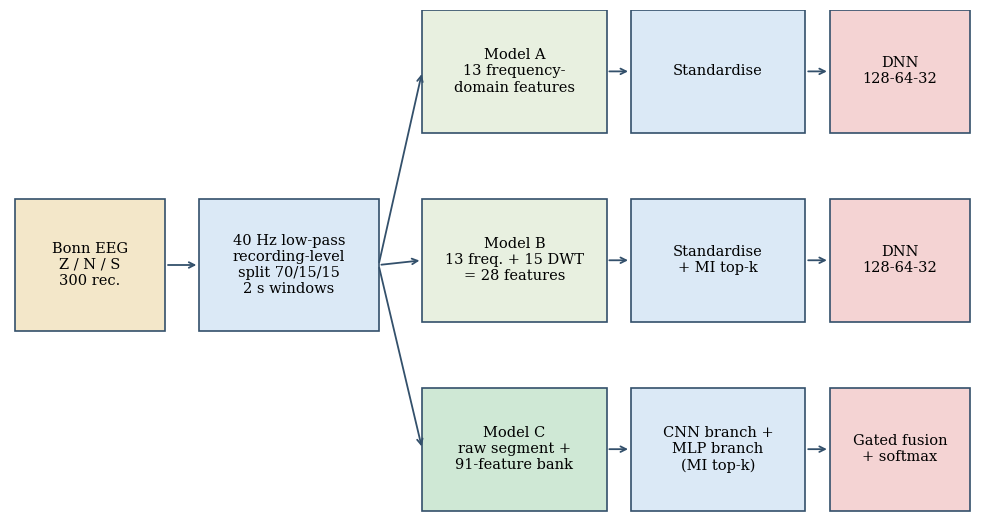

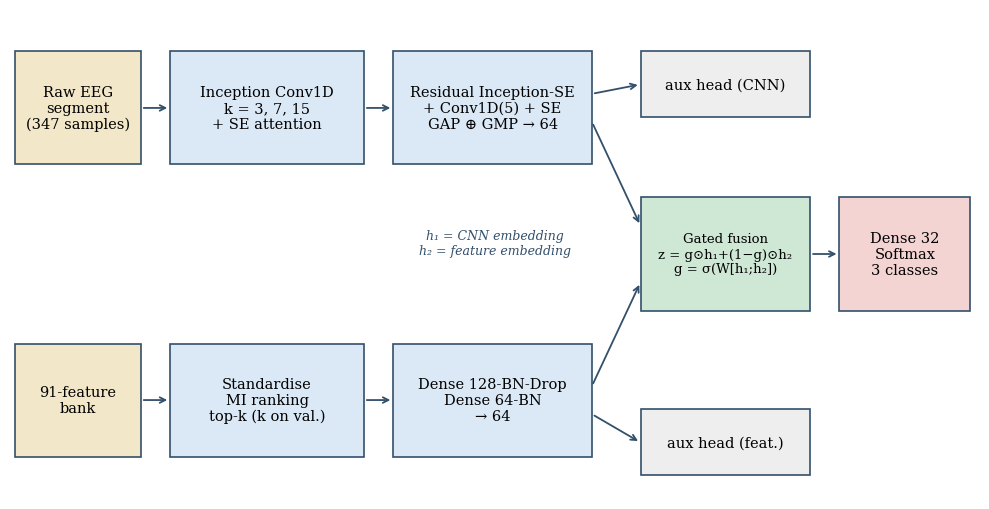

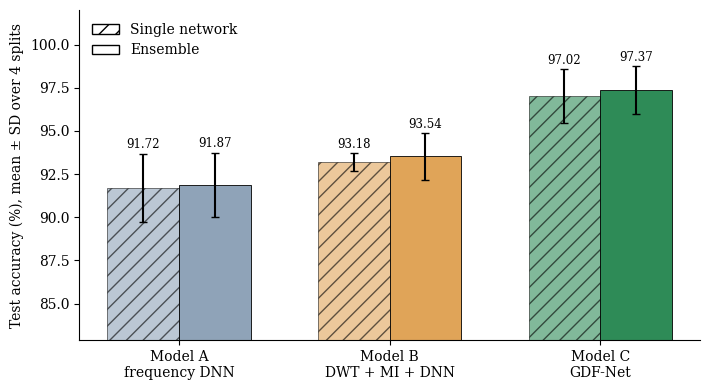

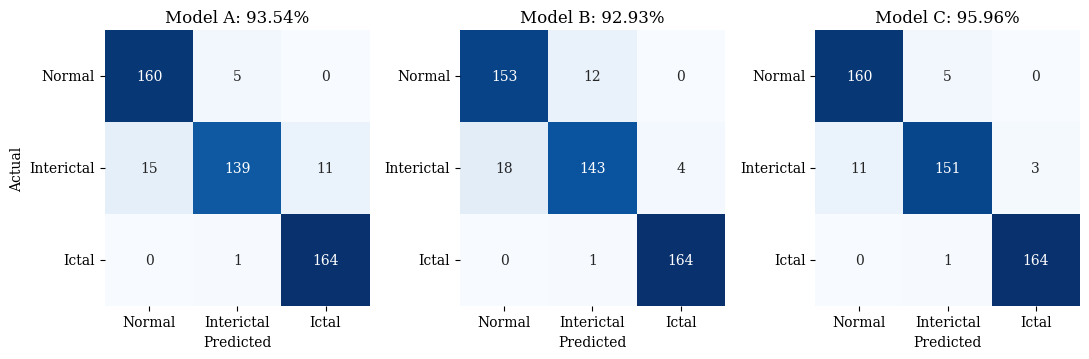

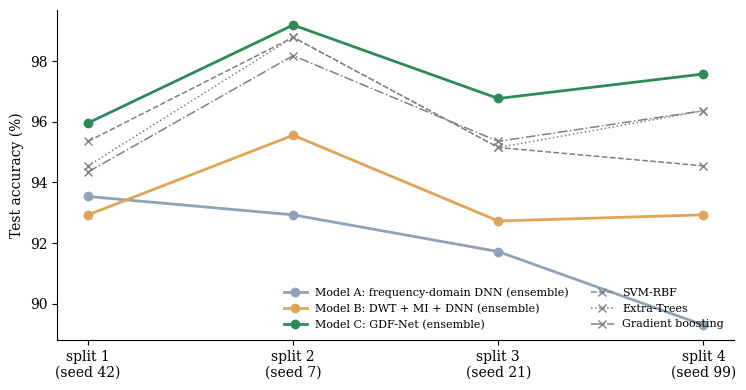

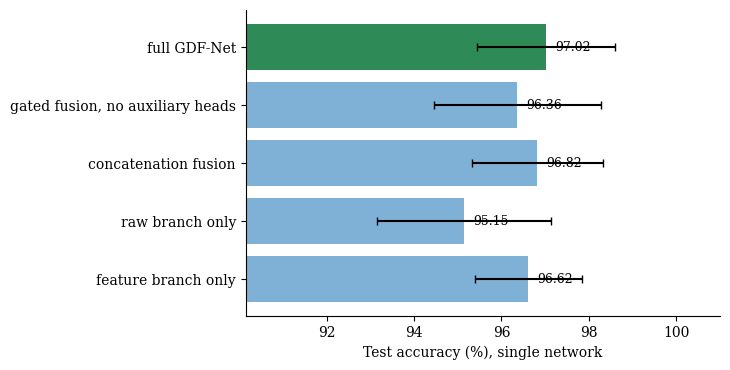

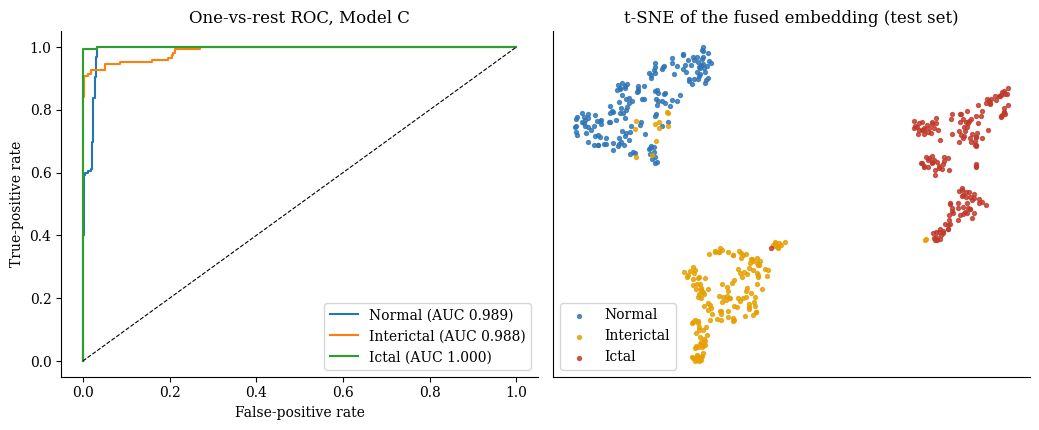

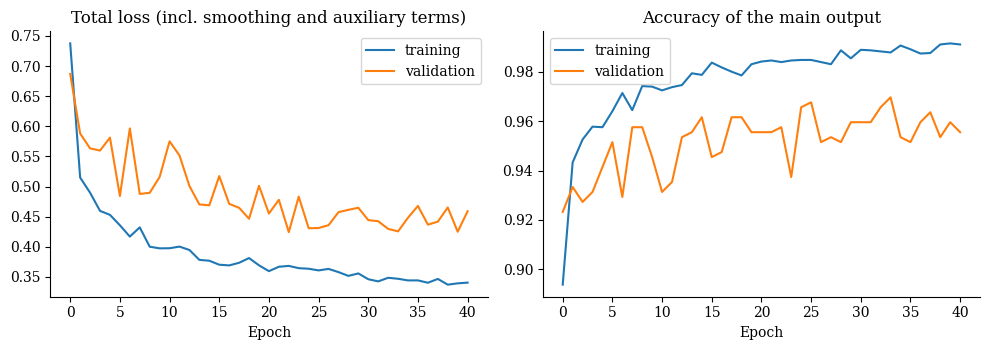

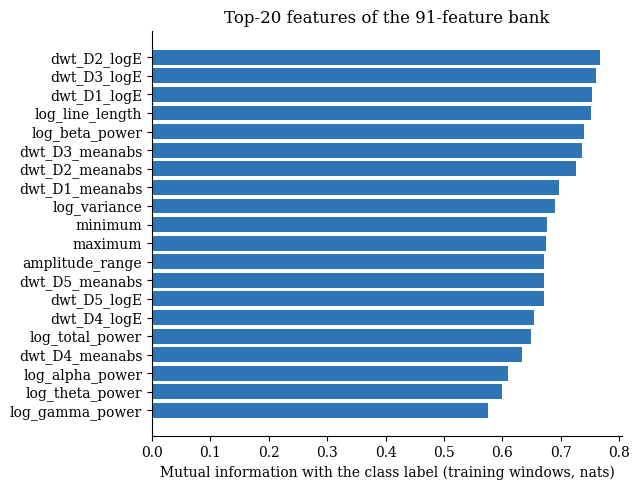

Mean gate value on the CNN embedding by true class (Normal, Interictal, Ictal): [0.521, 0.552, 0.654] | parameters: 110951 | epochs: 41


In [22]:
FIG = os.path.join(OUT, "figures"); os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"font.family": "serif", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
COL = {"A": "#8fa3b8", "B": "#e0a458", "C": "#2e8b57"}
def savefig(name): plt.tight_layout(); plt.savefig(os.path.join(FIG, name), dpi=300); plt.show()

# Fig 1 - pipeline of the three models
fig, ax = plt.subplots(figsize=(10, 5.4)); ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 5.4)
def box(x, y, w, h, t, c="#dbe9f6", fs=10.5): ax.add_patch(plt.Rectangle((x, y), w, h, fc=c, ec="#33506b", lw=1.2)); ax.text(x + w/2, y + h/2, t, ha="center", va="center", fontsize=fs)
def arr(x1, y1, x2, y2): ax.annotate("", (x2, y2), (x1, y1), arrowprops=dict(arrowstyle="->", color="#33506b", lw=1.3))
box(0.05, 2.0, 1.55, 1.4, "Bonn EEG\nZ / N / S\n300 rec.", "#f3e7c9"); box(1.95, 2.0, 1.85, 1.4, "40 Hz low-pass\nrecording-level\nsplit 70/15/15\n2 s windows"); arr(1.6, 2.7, 1.95, 2.7)
for y, nm, f, s_, m in [(4.0, "Model A", "13 frequency-\ndomain features", "Standardise", "DNN\n128-64-32"), (2.0, "Model B", "13 freq. + 15 DWT\n= 28 features", "Standardise\n+ MI top-k", "DNN\n128-64-32"),
                        (0.0, "Model C", "raw segment +\n91-feature bank", "CNN branch +\nMLP branch\n(MI top-k)", "Gated fusion\n+ softmax")]:
    box(4.25, y+0.1, 1.9, 1.3, f"{nm}\n{f}", "#cfe8d5" if nm == "Model C" else "#e8f0e0"); box(6.4, y+0.1, 1.8, 1.3, s_); box(8.45, y+0.1, 1.45, 1.3, m, "#f4d3d3")
    arr(6.15, y+0.75, 6.4, y+0.75); arr(8.2, y+0.75, 8.45, y+0.75); arr(3.8, 2.7, 4.25, y+0.75)
savefig("fig01_pipeline.png")

# Fig 2 - architecture of GDF-Net
fig, ax = plt.subplots(figsize=(10, 5.2)); ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 5.2)
def bx(x, y, w, h, t, c="#dbe9f6", fs=10.5): ax.add_patch(plt.Rectangle((x, y), w, h, fc=c, ec="#33506b", lw=1.2)); ax.text(x + w/2, y + h/2, t, ha="center", va="center", fontsize=fs)
bx(0.05, 3.55, 1.3, 1.2, "Raw EEG\nsegment\n(347 samples)", "#f3e7c9"); bx(1.65, 3.55, 2.0, 1.2, "Inception Conv1D\nk = 3, 7, 15\n+ SE attention"); bx(3.95, 3.55, 2.05, 1.2, "Residual Inception-SE\n+ Conv1D(5) + SE\nGAP ⊕ GMP → 64")
bx(0.05, 0.45, 1.3, 1.2, "91-feature\nbank", "#f3e7c9"); bx(1.65, 0.45, 2.0, 1.2, "Standardise\nMI ranking\ntop-k (k on val.)"); bx(3.95, 0.45, 2.05, 1.2, "Dense 128-BN-Drop\nDense 64-BN\n→ 64")
bx(6.5, 2.0, 1.75, 1.2, "Gated fusion\nz = g⊙h₁+(1−g)⊙h₂\ng = σ(W[h₁;h₂])", "#cfe8d5", 9.5); bx(8.55, 2.0, 1.35, 1.2, "Dense 32\nSoftmax\n3 classes", "#f4d3d3")
bx(6.5, 4.05, 1.75, 0.7, "aux head (CNN)", "#eeeeee"); bx(6.5, 0.25, 1.75, 0.7, "aux head (feat.)", "#eeeeee"); ax.text(5.0, 2.6, "h₁ = CNN embedding\nh₂ = feature embedding", ha="center", fontsize=9, style="italic", color="#33506b")
for q in [(1.35,4.15,1.65,4.15),(3.65,4.15,3.95,4.15),(1.35,1.05,1.65,1.05),(3.65,1.05,3.95,1.05),(6.0,4.0,6.5,2.9),(6.0,1.2,6.5,2.3),(8.25,2.6,8.55,2.6),(6.0,4.3,6.5,4.4),(6.0,0.9,6.5,0.6)]: arr(*q)
savefig("fig02_architecture.png")

# Fig 3 - comparison of A, B, C
fig, ax = plt.subplots(figsize=(7.2, 4)); w = 0.34
for kind, off, hatch, al in (("single", -w/2, "//", 0.6), ("ensemble", w/2, "", 1.0)):
    for i, (k, nm) in enumerate(MODELS_MAIN):
        a = acc_by_split(k, kind) * 100; sd = a.std(ddof=1) if len(a) > 1 else 0
        ax.bar(i + off, a.mean(), w, yerr=sd, capsize=3, color=COL[k], alpha=al, edgecolor="k", lw=0.6, hatch=hatch); ax.text(i + off, a.mean() + sd + 0.3, f"{a.mean():.2f}", ha="center", fontsize=8.5)
ax.set_xticks(range(3)); ax.set_xticklabels(["Model A\nfrequency DNN", "Model B\nDWT + MI + DNN", "Model C\nGDF-Net"]); ax.set_ylabel(f"Test accuracy (%), mean ± SD over {len(SPLIT_SEEDS)} splits")
lo = min(acc_by_split(k, kd).min() for k, _ in MODELS_MAIN for kd in ("single", "ensemble")) * 100; ax.set_ylim(max(0, lo - 6), 102)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(fc="white", ec="k", hatch="//", label="Single network"), Patch(fc="white", ec="k", label="Ensemble")], loc="upper left", frameon=False); savefig("fig03_comparison.png")

# Fig 4 - confusion matrices (primary split, ensembles)
fig, axs = plt.subplots(1, 3, figsize=(11, 3.7))
for a, (k, nm) in zip(axs, MODELS_MAIN):
    m = getm(PRIMARY_SEED, k, "ensemble"); sns.heatmap(np.array(m["cm"]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=a, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, vmin=0, vmax=165)
    a.set_title(f"{nm.split(':')[0]}: {m['acc']*100:.2f}%"); a.set_xlabel("Predicted"); a.set_ylabel("Actual" if k == "A" else ""); a.tick_params(axis="y", rotation=0)
savefig("fig04_confusion.png")

# Fig 5 - per-split accuracy
fig, ax = plt.subplots(figsize=(7.6, 4)); xs = np.arange(len(SPLIT_SEEDS))
for k, nm in MODELS_MAIN: ax.plot(xs, acc_by_split(k, "ensemble") * 100, "o-", color=COL[k], lw=2, label=nm + " (ensemble)")
for e, ls in zip(extra, ("--", ":", "-.")): ax.plot(xs, [getm(s, e, "single")["acc"] * 100 for s in SPLIT_SEEDS], ls, color="gray", marker="x", lw=1.1, label=e)
ax.set_xticks(xs); ax.set_xticklabels([f"split {i+1}\n(seed {s})" for i, s in enumerate(SPLIT_SEEDS)]); ax.set_ylabel("Test accuracy (%)"); ax.legend(fontsize=8, ncol=2, frameon=False, loc="lower right"); savefig("fig05_per_split.png")

# Fig 6 - ablation
ab = [(n.replace("Abl: ", ""), np.array([getm(s, n, "single")["acc"] for s in SPLIT_SEEDS if f"{n} | single" in ALL[s]["metrics"]]) * 100) for n in abl_names]
ab.append(("full GDF-Net", acc_by_split("C", "single") * 100))
fig, ax = plt.subplots(figsize=(7.4, 3.8))
ax.barh([a[0] for a in ab], [a[1].mean() for a in ab], xerr=[a[1].std(ddof=1) if len(a[1]) > 1 else 0 for a in ab], color=["#7fb0d6"] * 4 + [COL["C"]], capsize=3)
for i, a in enumerate(ab): ax.text(a[1].mean() + 0.2, i, f"{a[1].mean():.2f}", va="center", fontsize=9)
ax.set_xlim(max(0, min(a[1].mean() for a in ab) - 5), 101); ax.set_xlabel("Test accuracy (%), single network"); savefig("fig06_ablation.png")

if "_emb" in P0:
    # Fig 7 - ROC and t-SNE (Model C ensemble, primary split)
    pe = P0["probs"]["C"].mean(0); fig, axs = plt.subplots(1, 2, figsize=(10.5, 4.4))
    for c in range(3):
        fpr, tpr, _ = roc_curve((y0 == c).astype(int), pe[:, c]); axs[0].plot(fpr, tpr, label=f"{CLASS_NAMES[c]} (AUC {roc_auc_score((y0==c).astype(int), pe[:, c]):.3f})")
    axs[0].plot([0, 1], [0, 1], "k--", lw=0.8); axs[0].set_xlabel("False-positive rate"); axs[0].set_ylabel("True-positive rate"); axs[0].legend(loc="lower right"); axs[0].set_title("One-vs-rest ROC, Model C")
    Z = TSNE(n_components=2, perplexity=30, random_state=0, init="pca").fit_transform(P0["_emb"])
    for c, col in zip(range(3), ["#2e75b6", "#e69f00", "#c0392b"]): axs[1].scatter(*Z[y0 == c].T, s=8, c=col, label=CLASS_NAMES[c], alpha=0.8)
    axs[1].legend(); axs[1].set_title("t-SNE of the fused embedding (test set)"); axs[1].set_xticks([]); axs[1].set_yticks([]); savefig("fig07_roc_tsne.png")
    # Fig 8 - training curves
    h = P0["_hist"]; fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
    axs[0].plot(h["loss"], label="training"); axs[0].plot(h["val_loss"], label="validation"); axs[0].set_title("Total loss (incl. smoothing and auxiliary terms)"); axs[0].set_xlabel("Epoch"); axs[0].legend()
    ak = [k for k in h if k.endswith("accuracy") and not k.startswith("val")][0]
    axs[1].plot(h[ak], label="training"); axs[1].plot(h["val_" + ak], label="validation"); axs[1].set_title("Accuracy of the main output"); axs[1].set_xlabel("Epoch"); axs[1].legend(); savefig("fig08_training_curves.png")
    # Fig 9 - top-20 features by MI
    top = P0["_mi_order"][:20]; fig, ax = plt.subplots(figsize=(6.5, 5))
    ax.barh([FEAT_NAMES[i] for i in top][::-1], np.array(P0["mi_C"])[top][::-1], color="#2e75b6"); ax.set_xlabel("Mutual information with the class label (training windows, nats)"); ax.set_title("Top-20 features of the 91-feature bank"); savefig("fig09_mi_top20.png")
    print("Mean gate value on the CNN embedding by true class (Normal, Interictal, Ictal):", [round(g, 3) for g in P0["gate_by_class"]], "| parameters:", P0["n_params_C"], "| epochs:", P0["epochs_C"])

## 12. Export
Writes every table as CSV, a JSON with all metrics of every model and split, the per-segment class probabilities of the test sets (for re-analysis), the environment and configuration, and a zip of the output folder.

In [23]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items() if not str(k).startswith("_") and k not in ("probs", "y", "g", "mi_C")}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (float, np.floating)): return round(float(o), 5)
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.ndarray): return clean(o.tolist())
    return o
for n, t in (("table1_primary", T1), ("table2_all_splits", T2), ("table2b_per_split_accuracy", T2b.reset_index()), ("table3_per_class", T3), ("table4_ablation", T4),
             ("table5_feature_selection", T5), ("table6_mcnemar", T6), ("table7_bootstrap", T7), ("table8_paired_tests", T8)):
    t.to_csv(os.path.join(OUT, n + ".csv"), index=False)
CONFIG = {k: globals()[k] for k in ["FAST_TEST", "FS", "SEG_LEN", "LOWPASS_HZ", "PRIMARY_SEED", "SPLIT_SEEDS", "N_ENS", "EPOCHS", "BATCH", "LR", "LABEL_SMOOTHING", "PATIENCE", "ABLATION_SPLITS", "K_GRID_B", "K_GRID_C", "CLIP"]}
RESULTS = dict(environment=ENV, config=CONFIG, feature_names=FEAT_NAMES, a13_names=A13_NAMES, b15_names=B15_NAMES,
               primary_extra=dict(n_params_C=P0.get("n_params_C"), epochs_C=P0.get("epochs_C"), gate_by_class=P0.get("gate_by_class")),
               splits={str(s): clean(ALL[s]) for s in SPLIT_SEEDS},
               stats=dict(mcnemar=T6.to_dict("records"), bootstrap=T7.to_dict("records"), paired=T8.to_dict("records")))
json.dump(RESULTS, open(os.path.join(OUT, "results_all.json"), "w"), indent=1, default=str)
np.savez_compressed(os.path.join(OUT, "test_predictions.npz"), **{f"seed{s}__{k.replace(' ', '_')}": v for s in SPLIT_SEEDS for k, v in ALL[s]["probs"].items()},
                    **{f"seed{s}__labels": ALL[s]["y"] for s in SPLIT_SEEDS}, **{f"seed{s}__recording_ids": ALL[s]["g"] for s in SPLIT_SEEDS})
if not FAST_TEST:
    archive = shutil.make_archive("/content/eeg_results" if os.path.isdir("/content") else os.path.join(os.path.dirname(OUT), "eeg_results"), "zip", OUT); print("Archive:", archive)
    try:
        from google.colab import files; files.download(archive)
    except Exception as ex: print("Download the zip manually:", ex)
print("\nHEADLINE (segment-level test accuracy, %):")
display(T2[T2["Model"].str.startswith("Model")][["Model", "Setting", "Accuracy (%)", "Macro F1", "Recording acc. (%)"]])
print("Outputs written to", OUT)

Archive: /content/eeg_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


HEADLINE (segment-level test accuracy, %):


,Model,Setting,Accuracy (%),Macro F1,Recording acc. (%)
0,Model A: frequency-domain DNN,single,91.72 ± 1.97,0.9174 ± 0.0188,95.56 ± 3.14
1,Model B: DWT + MI + DNN,single,93.18 ± 0.53,0.9321 ± 0.0054,97.78 ± 1.81
2,Model C: GDF-Net,single,97.02 ± 1.58,0.9702 ± 0.0158,98.89 ± 1.28
3,Model A: frequency-domain DNN,ensemble,91.87 ± 1.88,0.9189 ± 0.0178,95.56 ± 3.14
4,Model B: DWT + MI + DNN,ensemble,93.54 ± 1.35,0.9355 ± 0.0134,97.78 ± 2.57
5,Model C: GDF-Net,ensemble,97.37 ± 1.38,0.9737 ± 0.0139,98.89 ± 1.28


Outputs written to /content/eeg_results
